# Create a wavelength lookup table for LoKI

In [1]:
import scipp as sc
import scippnexus as snx
from ess.reduce import unwrap
from ess.reduce.nexus.types import AnyRun, Position

## Setting up the workflow

Note here that for now, we have no chopper in the beamline.
This should be added in the next iteration.

In [2]:
source_position = sc.vector([0, 0, 0], unit='m')

wf = unwrap.LookupTableWorkflow()
wf[unwrap.DiskChoppers[AnyRun]] = {}
wf[Position[snx.NXsource, AnyRun]] = source_position
wf[unwrap.NumberOfSimulatedNeutrons] = 200_000  # Increase this number for more reliable results
wf[unwrap.SimulationSeed] = 1234
wf[unwrap.LtotalRange[AnyRun, snx.NXdetector]] = sc.scalar(5.0, unit="m"), sc.scalar(35.0, unit="m")
wf[unwrap.DistanceResolution] = sc.scalar(0.1, unit="m")
wf[unwrap.TimeResolution] = sc.scalar(250.0, unit='us')

## Compute the table

In [3]:
table = wf.compute(unwrap.LookupTable[AnyRun, snx.NXdetector])
table.array

<scipp.DataArray>
Dimensions: Sizes[distance:304, event_time_offset:287, ]
Coordinates:
* distance                  float64              [m]  (distance)  [4.8, 4.9, ..., 35, 35.1]
* event_time_offset         float64            [µs]  (event_time_offset)  [0, 249.75, ..., 71178.8, 71428.6]
Data:
                            float64             [Å]  (distance, event_time_offset)  [-nan, 0.158977, ..., 8.13542, 8.64043]  [-nan, 0.00210931, ..., 2.49451, 5.90787]

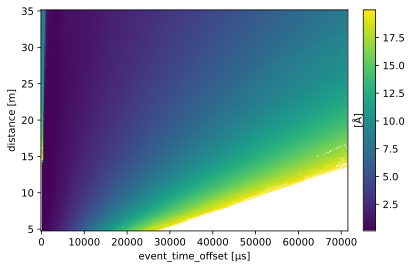

In [4]:
table.plot()

## Save to file

In [5]:
# Write to file
table.save_hdf5('loki-wavelength-lookup-table-no-choppers.h5')

Writing type '<class 'NoneType'>' to HDF5 not implemented, skipping.
